# 01 — Analyse exploratoire (version courte)

Exploration uniquement : aucune logique réutilisable ici (elle va dans `src/bankmlops/`).

Objectifs : comprendre la cible, la qualité des données, et montrer que la dérive entre les données anciennes (**référence**, 70 %) et récentes (**production**, 30 %) est réelle.

Prérequis : `poetry run dvc repro` (le CSV doit être dans `data/raw/`).

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from bankmlops.config import load_params, resolve_path

params = load_params()
df = pd.read_csv(resolve_path(params['data']['raw_csv']), sep=params['data']['separator'])
FIG_DIR = resolve_path('reports/figures')
FIG_DIR.mkdir(parents=True, exist_ok=True)
df.shape

(41188, 21)

## 1. Types et valeurs manquantes

In [2]:
print(df.dtypes.value_counts())
print('NaN :', int(df.isna().sum().sum()), '| doublons :', int(df.duplicated().sum()))
unknown = (df == 'unknown').sum()
unknown[unknown > 0].sort_values(ascending=False)

str        11
int64       5
float64     5
Name: count, dtype: int64
NaN : 0 | doublons : 12


default      8597
education    1731
housing       990
loan          990
job           330
marital        80
dtype: int64

## 2. La cible `y` : classes déséquilibrées

In [3]:
target = df['y'].value_counts()
rate = (df['y'] == 'yes').mean()
print(target.to_dict(), f'taux de yes = {rate:.2%}')

{'no': 36548, 'yes': 4640} taux de yes = 11.27%


## 3. `pdays = 999` (jamais contacté) et cardinalité des catégorielles

In [4]:
print(f"pdays == 999 : {(df['pdays'] == 999).mean():.1%} des lignes")
df.select_dtypes(exclude='number').nunique().sort_values(ascending=False)

pdays == 999 : 96.3% des lignes


job            12
month          10
education       8
day_of_week     5
marital         4
default         3
housing         3
poutcome        3
loan            3
contact         2
y               2
dtype: int64

## 4. Référence (70 % anciens) vs production (30 % récents)

Le fichier est trié par date (mai 2008 → nov. 2010) : on coupe **sans mélanger**.

In [5]:
cut = int(len(df) * params['split']['reference_ratio'])
ref, prod = df.iloc[:cut], df.iloc[cut:]
macro = ['euribor3m', 'emp.var.rate', 'nr.employed', 'cons.price.idx', 'cons.conf.idx']
comparison = pd.DataFrame({
    'référence': ref[macro].mean(), 'production': prod[macro].mean()
})
comparison.loc['taux de yes'] = [(ref['y'] == 'yes').mean(), (prod['y'] == 'yes').mean()]
comparison.loc['part contact = cellular'] = [
    (ref['contact'] == 'cellular').mean(), (prod['contact'] == 'cellular').mean()
]
print(f'référence : {len(ref)} lignes | production : {len(prod)} lignes')
comparison.round(3)

référence : 28831 lignes | production : 12357 lignes


,référence,production
euribor3m,4.685,1.138
emp.var.rate,1.000,-2.061
nr.employed,5208.861,5069.450
cons.price.idx,93.810,93.029
cons.conf.idx,-39.793,-42.158
taux de yes,0.056,0.246
part contact = cellular,0.522,0.899


## 5. Figures pour le rapport et les slides

In [6]:
# Palette et encre (référence du skill dataviz, mode clair)
BLUE, MUTED_BAR, INK, INK2, MUTED, SURFACE = (
    '#2a78d6', '#c3c2b7', '#0b0b0b', '#52514e', '#898781', '#fcfcfb'
)
plt.rcParams.update({
    'figure.facecolor': SURFACE, 'axes.facecolor': SURFACE, 'savefig.facecolor': SURFACE,
    'axes.edgecolor': MUTED, 'axes.labelcolor': INK2, 'xtick.color': MUTED,
    'ytick.color': MUTED, 'text.color': INK, 'font.size': 10,
    'axes.spines.top': False, 'axes.spines.right': False,
})

### Figure 1 — Déséquilibre de la cible

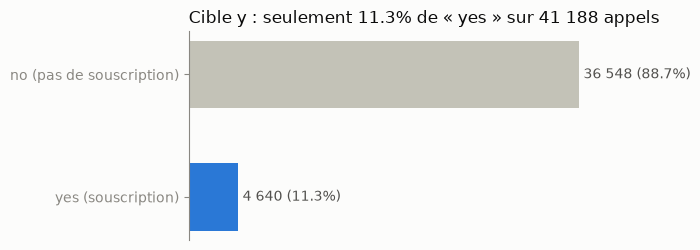

In [7]:
fig, ax = plt.subplots(figsize=(7, 2.6))
labels = ['no (pas de souscription)', 'yes (souscription)']
counts = [target['no'], target['yes']]
bars = ax.barh(labels, counts, color=[MUTED_BAR, BLUE], height=0.55)
for bar, n in zip(bars, counts, strict=True):
    ax.text(bar.get_width() + 400, bar.get_y() + bar.get_height() / 2,
            f'{n:,} ({n / len(df):.1%})'.replace(',', ' '), va='center', color=INK2)
ax.invert_yaxis()
ax.set_xlim(0, max(counts) * 1.25)
ax.xaxis.set_visible(False)
ax.spines['bottom'].set_visible(False)
ax.set_title(f'Cible y : seulement {rate:.1%} de « yes » sur {len(df):,} appels'
             .replace(',', ' '), loc='left', fontsize=12, color=INK)
fig.tight_layout()
fig.savefig(FIG_DIR / 'target_imbalance.png', dpi=150)
plt.show()

### Figure 2 — Dérive macro-économique dans le temps

Trois panneaux qui partagent le même axe (position dans le fichier = ordre chronologique), moyennes par blocs de ~1 000 appels. Zone grisée = « production ».

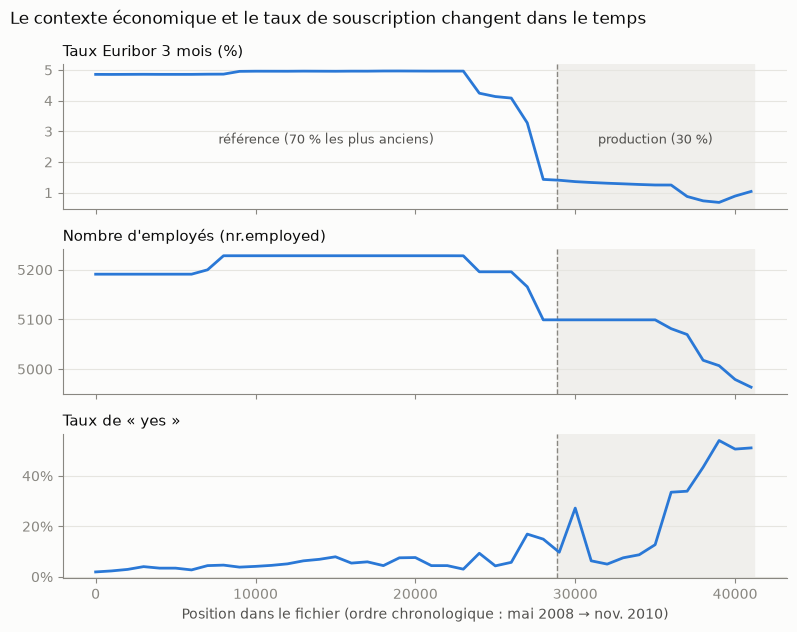

In [8]:
block = 1000
g = df.assign(bloc=df.index // block, yes=(df['y'] == 'yes').astype(float))
agg = g.groupby('bloc').agg(pos=('bloc', lambda s: s.index.min()), euribor3m=('euribor3m', 'mean'),
                            nr_employed=('nr.employed', 'mean'), yes=('yes', 'mean'))
panels = [('euribor3m', 'Taux Euribor 3 mois (%)'),
          ('nr_employed', 'Nombre d\'employés (nr.employed)'),
          ('yes', 'Taux de « yes »')]
fig, axes = plt.subplots(3, 1, figsize=(8, 6.4), sharex=True)
for ax, (col, title) in zip(axes, panels, strict=True):
    ax.axvspan(cut, len(df), color='#f0efec', zorder=0)
    ax.axvline(cut, color=MUTED, lw=1, ls='--')
    ax.plot(agg['pos'], agg[col], color=BLUE, lw=2)
    ax.set_title(title, loc='left', fontsize=10.5, color=INK)
    ax.grid(axis='y', color='#e6e5e0', lw=0.8)
axes[2].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:.0%}'))
axes[0].text(cut * 0.5, 2.6, 'référence (70 % les plus anciens)',
             ha='center', color=INK2, fontsize=9)
axes[0].text(cut + (len(df) - cut) / 2, 2.6, 'production (30 %)',
             ha='center', color=INK2, fontsize=9)
axes[2].set_xlabel('Position dans le fichier (ordre chronologique : mai 2008 → nov. 2010)')
fig.suptitle('Le contexte économique et le taux de souscription changent dans le temps',
             x=0.01, ha='left', fontsize=12, color=INK)
fig.tight_layout()
fig.savefig(FIG_DIR / 'macro_drift_over_time.png', dpi=150)
plt.show()

## 6. Observations

Voir le résumé dans `docs/PROGRESS.md` / la PR : les chiffres viennent des sorties ci-dessus.